# 06 · Analysis: can we trust what Indian health facilities say about themselves, and where is trusted care missing?

**In one minute**
- We scored **487,051 facility × service claims** (9,986 facilities, 2,531 services) by the evidence in each facility's own record: only **7% are Verified**, 44% are Claimed only.
- The score works: on **unseen hand-checked rows, 11 of 12 Verified were correct and 0 were wrong**.
- Linking to NFHS-5: **140 districts** have high mother & newborn need and **no Verified emergency C-section or NICU within 100 km** (Bastar 211 km, Rayagada 175 km).
- In **84 districts** a nearby facility (<25 km) *claims* emergency C-section but nobody has verified it: **verifying those claims is the cheapest way to bring care ~125 km closer**.

**Sections:** 1 setup · 2-3 Exploration (data quality, claims vs evidence) · 4 Modeling + validation · 5-8 Impact (distance to trusted care, need × distance, verification unlock) · 9 findings and recommendations.

**Inputs:** silver_facilities, gold_facility_services (+ _v1), verify_results_v1/v2/v3, bronze_nfhs_5_district_health_indicators, gold_location_lookup. **Output:** analysis_district_access (one row per NFHS district).

In [0]:
# 1. Setup: load the tables this analysis uses (all built by notebooks 01-05)
import re, difflib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
T = lambda n: spark.table(f"workspace.default.{n}").toPandas()
ORDER, COLORS = ["Verified", "Likely", "Claimed only"], ["#2e7d32", "#f9a825", "#bdbdbd"]
bronze_n = spark.table("workspace.default.bronze_facilities").count()
silver = T("silver_facilities")
gold = (spark.table("workspace.default.gold_facility_services")
        .select("unique_id", "service", "service_label", "service_source", "trust_level", "trust_score", "loc_lat", "loc_lon")
        .toPandas())
gold_v1 = spark.table("workspace.default.gold_facility_services_v1").groupBy("trust_level").count().toPandas()
ver = pd.concat([T(f"verify_results_v{i}").assign(round=i) for i in (1, 2, 3)], ignore_index=True)
nfhs = T("bronze_nfhs_5_district_health_indicators")
lookup = T("gold_location_lookup")
print(f"facilities: bronze {bronze_n:,} -> silver {len(silver):,} | gold facility x service rows {len(gold):,} "
      f"({gold['service'].nunique():,} services) | hand-checked rows {len(ver)} | NFHS-5 districts {len(nfhs)}")

facilities: bronze 10,088 -> silver 9,997 | gold facility x service rows 487,051 (2,531 services) | hand-checked rows 150 | NFHS-5 districts 706


21% of facilities carry at least one data-quality warning
website check on the hand-checked facilities (rounds 2-3): {'confirmed': 32, 'not-found': 15, 'no-site': 3}


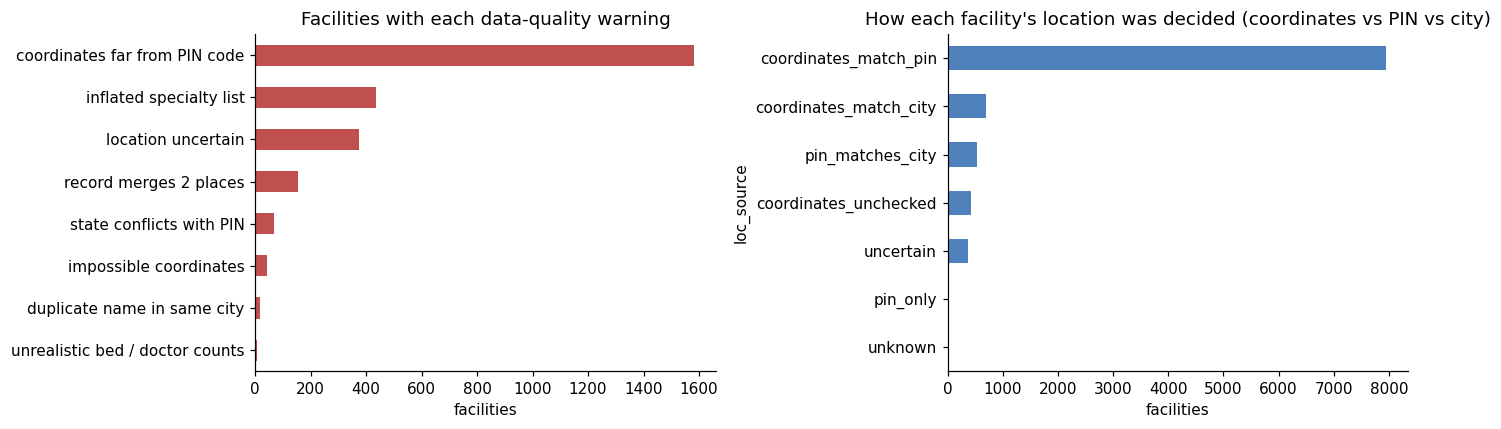

In [0]:
# 2. EXPLORATION: how messy is the data? Every field is a claim, so we FLAG problems instead of deleting records
FLAGS = {"flag_coords_far_from_pin": "coordinates far from PIN code", "flag_location_uncertain": "location uncertain",
         "flag_too_many_specialties": "inflated specialty list", "flag_mixed_identity": "record merges 2 places",
         "flag_bad_coords": "impossible coordinates", "flag_state_mismatch": "state conflicts with PIN",
         "flag_duplicate": "duplicate name in same city", "flag_implausible_counts": "unrealistic bed / doctor counts"}
fc = pd.Series({lab: int(silver[c].fillna(False).astype(bool).sum()) for c, lab in FLAGS.items() if c in silver}).sort_values()
print(f"{(silver['n_flags'] > 0).mean():.0%} of facilities carry at least one data-quality warning")
web = ver["web"].dropna().value_counts() if "web" in ver else pd.Series(dtype=int)
print("website check on the hand-checked facilities (rounds 2-3):", web.to_dict())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
fc.plot.barh(ax=ax[0], color="#c0504d"); ax[0].set_title("Facilities with each data-quality warning"); ax[0].set_xlabel("facilities")
silver["loc_source"].value_counts().sort_values().plot.barh(ax=ax[1], color="#4f81bd")
ax[1].set_title("How each facility's location was decided (coordinates vs PIN vs city)"); ax[1].set_xlabel("facilities")
plt.tight_layout(); plt.show()

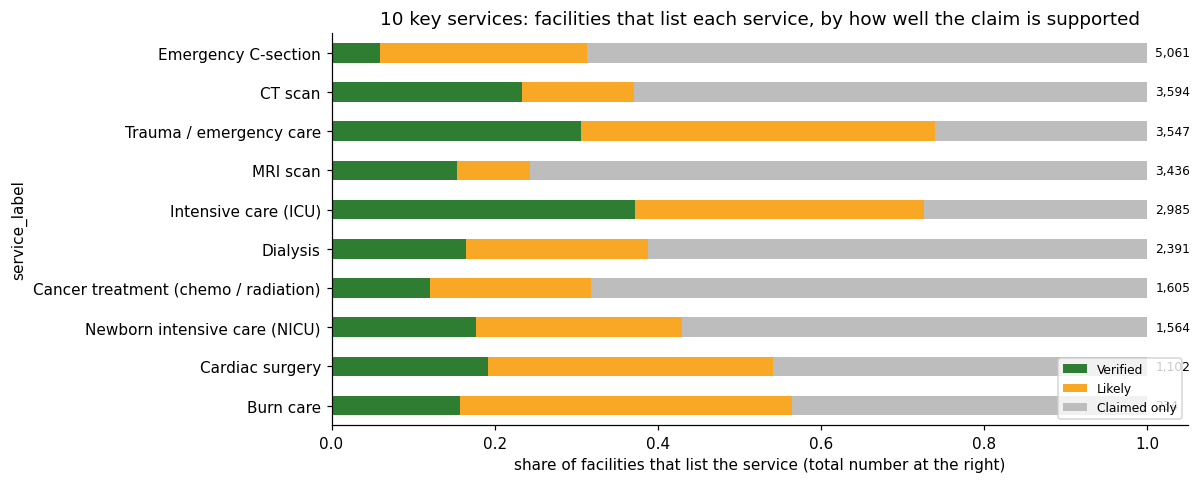

all 2,531 services together: Verified 7%, Likely 49%, Claimed only 44%


In [0]:
# 3. EXPLORATION: claims vs evidence. Most claimed services have NO direct evidence in the facility's own records
cur = gold[gold["service_source"] == "curated"]
tab = pd.crosstab(cur["service_label"], cur["trust_level"]).reindex(columns=ORDER, fill_value=0)
tab = tab.loc[tab.sum(axis=1).sort_values().index]
ax = tab.div(tab.sum(axis=1), axis=0).plot.barh(stacked=True, color=COLORS, figsize=(11, 4.5))
ax.set_title("10 key services: facilities that list each service, by how well the claim is supported")
ax.set_xlabel("share of facilities that list the service (total number at the right)")
for i, n in enumerate(tab.sum(axis=1)):
    ax.text(1.01, i, f"{n:,}", va="center", fontsize=8)
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()
allv = gold["trust_level"].value_counts(normalize=True).reindex(ORDER)
print("all 2,531 services together:", ", ".join(f"{k} {v:.0%}" for k, v in allv.items()))

              v1 (first rules)  v2 (after verification fixes)
trust_level                                                  
Verified                 17645                          35753
Likely                  192144                         238823
Claimed only            255941                         212475 

Hand-checked rows by the level the system gave at the time (round 1 = v1, round 2 = v2 on unseen rows, round 3 = rows Verified only by the last fix):
verdict             Yes  Unsure  No  rows  % Yes  % No
round trust_level                                     
1     Claimed only    8      12   4    24   33.0  17.0
      Likely         19      13   2    34   56.0   6.0
      Verified       30       7   3    40   75.0   8.0
2     Claimed only    2       5   1     8   25.0  12.0
      Likely          4       3   3    10   40.0  30.0
      Verified       11       1   0    12   92.0   0.0
3     Verified       15       4   0    19   79.0   0.0


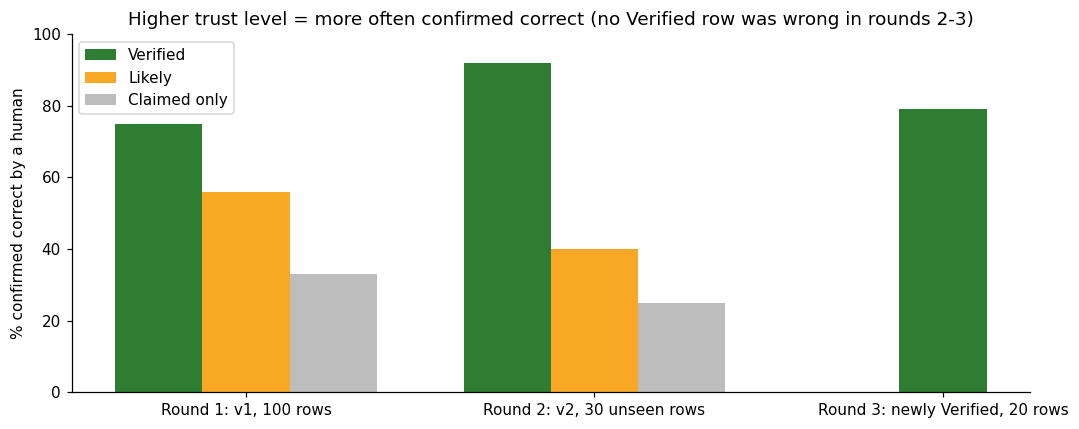

In [0]:
# 4. MODELING + VALIDATION: does the trust level mean something? Humans checked 150 rows against the record and the web
v1 = gold_v1.set_index("trust_level")["count"].reindex(ORDER)
v2 = gold["trust_level"].value_counts().reindex(ORDER)
print(pd.DataFrame({"v1 (first rules)": v1, "v2 (after verification fixes)": v2}).to_string(), "\n")
j = ver[ver["verdict"].isin(["Yes", "No", "Unsure"])]
res = j.groupby(["round", "trust_level"])["verdict"].value_counts().unstack(fill_value=0).reindex(columns=["Yes", "Unsure", "No"], fill_value=0)
res["rows"] = res.sum(axis=1)
for c in ["Yes", "No"]:
    res[f"% {c}"] = (100 * res[c] / res["rows"]).round(0)
print("Hand-checked rows by the level the system gave at the time (round 1 = v1, round 2 = v2 on unseen rows, round 3 = rows Verified only by the last fix):")
print(res.to_string())
fig, ax = plt.subplots(figsize=(10, 4))
w = 0.25
for k, lvl in enumerate(ORDER):
    vals = [res.loc[(r, lvl), "% Yes"] if (r, lvl) in res.index else np.nan for r in (1, 2)]
    ax.bar(np.arange(2) + (k - 1) * w, vals, w, label=lvl, color=COLORS[k])
ax.bar(2, res.loc[(3, "Verified"), "% Yes"], w, color=COLORS[0])
ax.set_xticks(range(3), ["Round 1: v1, 100 rows", "Round 2: v2, 30 unseen rows", "Round 3: newly Verified, 20 rows"])
ax.set_ylabel("% confirmed correct by a human"); ax.set_ylim(0, 100)
ax.set_title("Higher trust level = more often confirmed correct (no Verified row was wrong in rounds 2-3)")
ax.legend(); plt.tight_layout(); plt.show()

NFHS districts placed on the map: 655 of 706
Emergency C-section: median district is 74 km from the nearest Verified facility; 223 districts are more than 100 km away
Newborn ICU: median district is 66 km from the nearest Verified facility; 211 districts are more than 100 km away
Dialysis: median district is 61 km from the nearest Verified facility; 178 districts are more than 100 km away


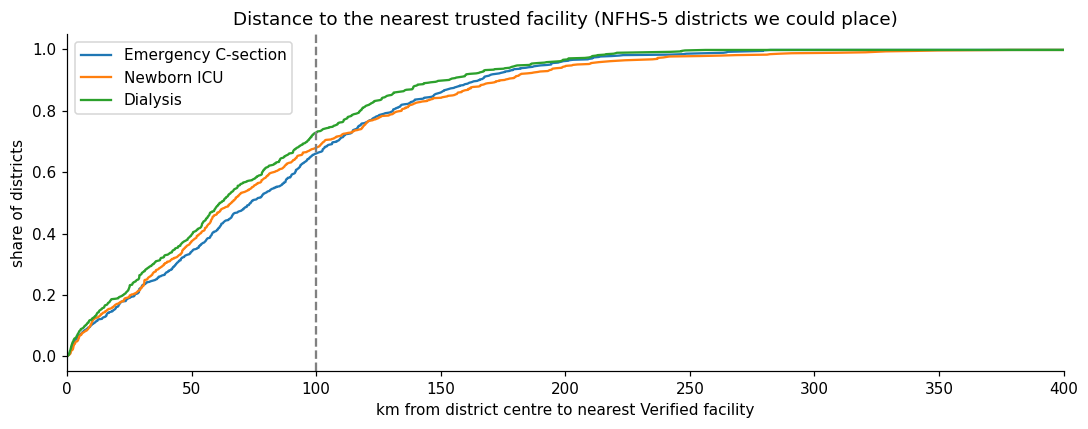

In [0]:
# 5. IMPACT (a): how far is each district from the nearest VERIFIED facility for life-saving services?
key = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
dl = lookup[lookup["place_type"] == "district"].sort_values("n_points", ascending=False).copy()
dl["skey"] = dl["state"].map(key)
exact = dl.drop_duplicates(["place_key", "skey"]).set_index(["place_key", "skey"])[["lat", "lon"]]
alt = dl.drop_duplicates("place_key").set_index("place_key")[["lat", "lon"]]
nf = nfhs.copy()
nf["dkey"], nf["skey"] = nf["district_name"].map(key), nf["state_ut"].map(key)
def place_district(r):
    if (r.dkey, r.skey) in exact.index:
        return exact.loc[(r.dkey, r.skey)].to_numpy(float)
    if r.dkey in alt.index:
        return alt.loc[r.dkey].to_numpy(float)
    cands = dl[dl["skey"] == r.skey]                                   # same state, closest spelling
    hit = difflib.get_close_matches(r.dkey, cands["place_key"].tolist(), n=1, cutoff=0.8)
    return cands[cands["place_key"] == hit[0]].iloc[0][["lat", "lon"]].to_numpy(float) if hit else np.array([np.nan, np.nan])
nf[["lat", "lon"]] = np.vstack([place_district(r) for r in nf.itertuples()])
print(f"NFHS districts placed on the map: {nf['lat'].notna().sum()} of {len(nf)}")
def nearest_km(svc, levels):
    p = gold[(gold["service"] == svc) & gold["trust_level"].isin(levels)].dropna(subset=["loc_lat", "loc_lon"])
    la, lo = np.radians(p["loc_lat"].to_numpy(float))[None, :], np.radians(p["loc_lon"].to_numpy(float))[None, :]
    LA, LO = np.radians(nf["lat"].to_numpy(float))[:, None], np.radians(nf["lon"].to_numpy(float))[:, None]
    a = np.sin((la - LA) / 2) ** 2 + np.cos(LA) * np.cos(la) * np.sin((lo - LO) / 2) ** 2
    return (2 * 6371 * np.arcsin(np.sqrt(a))).min(axis=1)
KEY = {"emergency_c_section": "Emergency C-section", "nicu": "Newborn ICU", "dialysis": "Dialysis"}
for s in KEY:
    nf[f"km_verified_{s}"] = nearest_km(s, ["Verified"])
    nf[f"km_any_{s}"] = nearest_km(s, ORDER)
placed = nf[nf["lat"].notna()]
fig, ax = plt.subplots(figsize=(10, 4))
for s, lab in KEY.items():
    d = np.sort(placed[f"km_verified_{s}"].to_numpy())
    ax.plot(d, np.arange(1, len(d) + 1) / len(d), label=lab)
    print(f"{lab}: median district is {np.median(d):.0f} km from the nearest Verified facility; "
          f"{(d > 100).sum()} districts are more than 100 km away")
ax.axvline(100, ls="--", c="grey"); ax.set_xlim(0, 400); ax.set_xlabel("km from district centre to nearest Verified facility")
ax.set_ylabel("share of districts"); ax.set_title("Distance to the nearest trusted facility (NFHS-5 districts we could place)"); ax.legend()
plt.tight_layout(); plt.show()

In [0]:
# 6. IMPACT (b): where is the NEED high and trusted care FAR? (NFHS-5 need indicators x distance)
num = lambda c: pd.to_numeric(nf[c].astype(str).str.replace(r"[^0-9.]", "", regex=True), errors="coerce")
nf["institutional_births_pct"] = num("institutional_birth_5y_pct")
nf["pregnant_anaemic_pct"] = num("pregnant_w15_49_who_are_anaemic_lt_11_0_g_dl_22_pct")
nf["high_blood_sugar_pct"] = (num("w15_plus_with_high_or_very_high_gt_140_mg_dl_blood_sugar_or_pct")
                              + num("m15_plus_with_high_or_very_high_gt_140_mg_dl_blood_sugar_or_pct")) / 2
nf["insured_pct"] = num("hh_member_covered_health_insurance_pct")
pr = lambda s: s.rank(pct=True)
nf["mother_newborn_need"] = (pr(100 - nf["institutional_births_pct"]) + pr(nf["pregnant_anaemic_pct"])) / 2
nf["mother_newborn_gap_km"] = nf[["km_verified_emergency_c_section", "km_verified_nicu"]].max(axis=1)
nf["kidney_need"] = pr(nf["high_blood_sugar_pct"])
show = ["district_name", "state_ut", "institutional_births_pct", "pregnant_anaemic_pct", "km_verified_emergency_c_section",
        "km_any_emergency_c_section", "km_verified_nicu"]
moth = nf[(nf["mother_newborn_gap_km"] > 100) & (nf["mother_newborn_need"] >= 0.5)].sort_values("mother_newborn_need", ascending=False)
print(f"{len(moth)} districts have above-median mother & newborn need AND are >100 km from a Verified emergency C-section or NICU. Top 15:")
display(moth[show].head(15).round(1))
kid = nf[(nf["km_verified_dialysis"] > 100) & (nf["kidney_need"] >= 0.5)].sort_values("kidney_need", ascending=False)
print(f"{len(kid)} districts have above-median high blood sugar (diabetes -> kidney failure) AND are >100 km from Verified dialysis")
display(kid[["district_name", "state_ut", "high_blood_sugar_pct", "km_verified_dialysis", "km_any_dialysis"]].head(10).round(1))
out = nf[["district_name", "state_ut", "lat", "lon", "institutional_births_pct", "pregnant_anaemic_pct", "high_blood_sugar_pct",
          "insured_pct", "mother_newborn_need", "kidney_need"] + [c for c in nf if c.startswith("km_")]].copy()
out["district_name"] = out["district_name"].str.strip()
spark.createDataFrame(out).write.mode("overwrite").option("overwriteSchema", "true").saveAsTable("workspace.default.analysis_district_access")
print("saved workspace.default.analysis_district_access (one row per NFHS district: need indicators + km to nearest trusted care)")

140 districts have above-median mother & newborn need AND are >100 km from a Verified emergency C-section or NICU. Top 15:


district_name,state_ut,institutional_births_pct,pregnant_anaemic_pct,km_verified_emergency_c_section,km_any_emergency_c_section,km_verified_nicu
Bastar,Chhattisgarh,63.5,79.0,211.3,91.9,209.5
Rayagada,Odisha,68.9,77.3,174.9,32.8,171.6
Purnia,Bihar,68.9,74.6,134.1,0.3,68.2
Unakoti,Tripura,71.5,76.7,106.3,58.2,134.3
Araria,Bihar,66.2,70.5,117.9,41.0,80.5
Dhubri,Assam,64.2,69.7,164.7,20.6,138.8
Gajapati,Odisha,76.4,77.4,168.3,75.3,165.3
Kodagaon,Chhattisgarh,78.7,87.6,174.1,100.4,182.1
Pakur,Jharkhand,64.6,67.5,81.5,50.5,132.9
Dhule,Maharastra,77.2,70.6,16.9,16.9,101.8


82 districts have above-median high blood sugar (diabetes -> kidney failure) AND are >100 km from Verified dialysis


district_name,state_ut,high_blood_sugar_pct,km_verified_dialysis,km_any_dialysis
Prakasam,Andhra Pradesh,26.7,160.1,57.7
East Godavari,Andhra Pradesh,24.6,138.7,7.3
Yanam,Puducherry,23.4,140.6,40.6
Karaikal,Puducherry,22.6,118.4,70.1
West Godavari,Andhra Pradesh,21.4,102.8,19.2
Suryapet,Telangana,20.8,114.7,89.3
Munger,Bihar,20.6,135.1,39.3
Y.S.R.,Andhra Pradesh,20.4,117.1,25.1
Sepahijala,Tripura,20.2,210.8,40.4
Nagapattinam,Tamil Nadu,19.6,117.1,68.0


saved workspace.default.analysis_district_access (one row per NFHS district: need indicators + km to nearest trusted care)


            service  districts  km_saved_median                                           example_districts
Emergency C-section         84            129.0 Thoubal, Imphal East, Bishnupur, Imphal West, Churachandpur
        Newborn ICU         31            127.0            Lunglei, Jaisalmer, Dhemaji, West Tripura, Latur
           Dialysis         34            125.0                 Jaisalmer, Shahdol, Katni, Surguja, Bikaner


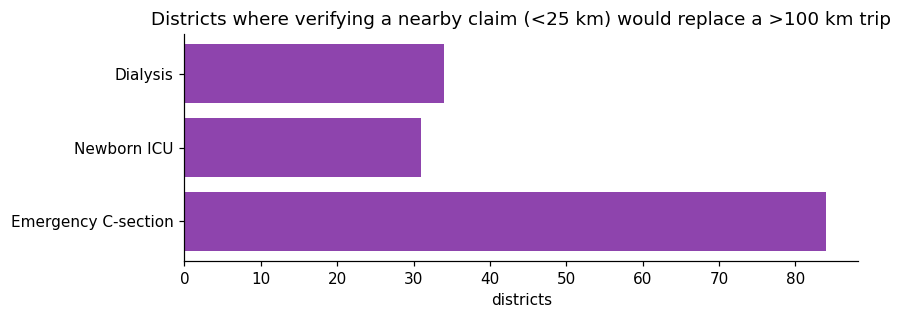

In [0]:
# 7. IMPACT (c): the cheapest fix is often VERIFICATION, not construction
# districts where some facility within 25 km CLAIMS the service, but the nearest Verified one is > 100 km away:
# one phone call / inspection of those nearby facilities could bring trusted care 75+ km closer
rows = []
for s, lab in KEY.items():
    g_ = placed[(placed[f"km_any_{s}"] <= 25) & (placed[f"km_verified_{s}"] > 100)]
    rows.append(dict(service=lab, districts=len(g_), km_saved_median=round(float((g_[f"km_verified_{s}"] - g_[f"km_any_{s}"]).median()), 0)
                     if len(g_) else 0, example_districts=", ".join(g_.sort_values(f"km_verified_{s}", ascending=False)["district_name"].str.strip().head(5))))
unlock = pd.DataFrame(rows)
print(unlock.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(unlock["service"], unlock["districts"], color="#8e44ad")
ax.set_title("Districts where verifying a nearby claim (<25 km) would replace a >100 km trip"); ax.set_xlabel("districts")
plt.tight_layout(); plt.show()

In [0]:
# 8. Numbers used in the summary at the top and in the video
print("top mother & newborn priority districts:")
print(moth[["district_name", "state_ut", "institutional_births_pct", "pregnant_anaemic_pct", "km_verified_emergency_c_section", "km_verified_nicu", "km_any_emergency_c_section"]].head(10).round(0).to_string(index=False))
print("\nstates with the most priority districts (mother & newborn):", moth["state_ut"].str.strip().value_counts().head(6).to_dict())
print("insurance coverage, priority vs other districts:", round(moth["insured_pct"].median(), 1), "vs", round(nf.loc[~nf.index.isin(moth.index), "insured_pct"].median(), 1))

top mother & newborn priority districts:
district_name     state_ut  institutional_births_pct  pregnant_anaemic_pct  km_verified_emergency_c_section  km_verified_nicu  km_any_emergency_c_section
      Bastar  Chhattisgarh                      64.0                  79.0                            211.0             209.0                        92.0
    Rayagada        Odisha                      69.0                  77.0                            175.0             172.0                        33.0
      Purnia         Bihar                      69.0                  75.0                            134.0              68.0                         0.0
     Unakoti       Tripura                      72.0                  77.0                            106.0             134.0                        58.0
      Araria         Bihar                      66.0                  70.0                            118.0              80.0                        41.0
      Dhubri         Assam         

## 9. What we found, and what we recommend

**Findings**
1. **Claims cannot be taken at face value.** 21% of facility records carry at least one data-quality warning. Of 50 hand-checked facilities, 15 websites did not mention the claimed service and 3 had no working website.
2. **Most claims have no direct evidence.** Across 487,051 facility × service claims (2,531 services), only 7% are Verified, 49% Likely and 44% Claimed only.
3. **The trust level is meaningful.** In hand checks, correctness rises with the level (round 1: 75% / 56% / 33%). On 12 unseen Verified rows, 11 were correct and 0 wrong; 20 rows that became Verified after our last fix: 15 correct, 0 wrong.
4. **Trusted life-saving care is far away for many districts.** The median NFHS-5 district is 74 km from the nearest Verified emergency C-section, 66 km from a Verified newborn ICU and 61 km from Verified dialysis; 223, 211 and 178 of 655 districts are more than 100 km away.
5. **Need and distance overlap.** 140 districts have above-median mother & newborn need (low institutional births, high anaemia in pregnancy) and are >100 km from a Verified emergency C-section or NICU, e.g. Bastar (211 km), Rayagada (175 km), Gajapati (168 km), Dhubri (165 km). The states with the most such districts are Madhya Pradesh (21), Assam (15), Chhattisgarh (11) and Odisha (10). 82 districts have above-median high blood sugar and no Verified dialysis within 100 km.
6. **Often the gap is verification, not buildings.** In 84 districts a facility within 25 km *claims* emergency C-section while the nearest Verified one is >100 km away (median 129 km difference); 31 districts for NICU, 34 for dialysis.
7. **Insurance without trusted care.** These priority districts already have higher health-insurance coverage (median 40% of households vs 35% elsewhere).

**Recommendations**
1. **Verify before you build.** State health departments / NHM should first verify (call, document check, visit) the facilities that claim emergency C-section, NICU and dialysis in the 84 / 31 / 34 "unlock" districts. It is the cheapest way to bring trusted care ~125 km closer.
2. **Route emergencies by trust level.** Ambulance (108) and referral systems should send emergencies to Verified facilities and show Claimed-only ones with a warning, with the evidence quote (column explanation in gold_facility_services).
3. **Target new capacity where need is high and no claim exists nearby**: first referral units, newborn care units and Pradhan Mantri National Dialysis Programme units for the 140 / 82 priority districts (table analysis_district_access), starting with Bastar, Rayagada, Gajapati, Dhubri and Kondagaon.
4. **Tie insurance empanelment to evidence.** PM-JAY empanelment should require the same evidence our model rewards (equipment with counts, beds, 24/7 staffing). This also keeps the trust score up to date.
5. **Publish structured service data.** Concrete numbers ("10 dialysis machines", "20-bed NICU") were the strongest trust signal; a simple mandatory format would make most claims checkable.

**Limits (honest uncertainty)**
- The data covers ~10,000 facilities, not every facility in India: "far from a Verified facility *in this data*" is a priority list for verification, not proof that no care exists.
- District centres come from the PIN directory; 51 of 706 NFHS districts could not be placed.
- Hand checks are small (150 rows), so the accuracy numbers have wide uncertainty (e.g. 11/12 correct).